<a href="https://colab.research.google.com/github/CChinmayi18/red_black_tree_dsa_/blob/main/nlp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q --upgrade "numpy<2.0" "scipy<1.13" "gensim==4.3.3" "scikit-learn" pandas


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done


In [14]:
import numpy as np
import pandas as pd
import sklearn
import gensim

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Gensim:", gensim.__version__)

print("All libraries imported successfully!")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1
Gensim: 4.4.0
All libraries imported successfully!


In [15]:
data = {
    "text": [
        # Positive reviews
        "This movie is excellent and wonderful",
        "I really enjoyed this amazing film",
        "The movie was fantastic and interesting",
        "The acting was brilliant and impressive",
        "I loved this beautiful movie",
        "The story was excellent and engaging",
        "The film was very enjoyable",
        "Amazing performance by all actors",
        "This is a great and entertaining movie",
        "I had a wonderful experience watching it",
        "The movie was outstanding and excellent",
        "The actors delivered a fantastic performance",
        "I absolutely loved the film",
        "The movie was enjoyable and exciting",
        "A brilliant story with excellent acting",

        # Negative reviews
        "This movie is terrible and boring",
        "I really disliked this awful film",
        "The movie was disappointing and dull",
        "The acting was poor and unimpressive",
        "I hated this horrible movie",
        "The story was boring and confusing",
        "The film was very disappointing",
        "Terrible performance by all actors",
        "This is a bad and boring movie",
        "I had a horrible experience watching it",
        "The movie was awful and disappointing",
        "The actors delivered a poor performance",
        "I absolutely disliked the film",
        "The movie was dull and uninteresting",
        "A terrible story with poor acting",

        # Neutral reviews
        "The movie was released last week",
        "I watched the film yesterday",
        "The movie has two main characters",
        "The film is about a family",
        "The story takes place in a city",
        "The movie lasts for two hours",
        "The actors participated in the film",
        "The film was shown in the theatre",
        "The movie contains several scenes",
        "I watched the movie with my friends",
        "The director announced a new film",
        "The movie was produced last year",
        "The film includes music and dialogue",
        "The story has different characters",
        "The movie is available online"
    ],

    "sentiment": (
        ["Positive"] * 15 +
        ["Negative"] * 15 +
        ["Neutral"] * 15
    )
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["sentiment"].value_counts())

Dataset created successfully!
                                      text sentiment
0    This movie is excellent and wonderful  Positive
1       I really enjoyed this amazing film  Positive
2  The movie was fantastic and interesting  Positive
3  The acting was brilliant and impressive  Positive
4             I loved this beautiful movie  Positive

Dataset shape: (45, 2)

Class distribution:
sentiment
Positive    15
Negative    15
Neutral     15
Name: count, dtype: int64


In [19]:
print(type(df))
print(df.columns)
print(df.head())

<class 'pandas.DataFrame'>
Index(['text', 'sentiment'], dtype='str')
                                      text sentiment
0    This movie is excellent and wonderful  Positive
1       I really enjoyed this amazing film  Positive
2  The movie was fantastic and interesting  Positive
3  The acting was brilliant and impressive  Positive
4             I loved this beautiful movie  Positive


In [18]:
print(type(df))
print(df.columns)
print(df.head())

<class 'pandas.DataFrame'>
Index(['text', 'sentiment'], dtype='str')
                                      text sentiment
0    This movie is excellent and wonderful  Positive
1       I really enjoyed this amazing film  Positive
2  The movie was fantastic and interesting  Positive
3  The acting was brilliant and impressive  Positive
4             I loved this beautiful movie  Positive


In [21]:
import re
import pandas as pd

data = {
    "text": [
        "This movie is excellent and wonderful",
        "I really enjoyed this amazing film",
        "The movie was fantastic and interesting",
        "The acting was brilliant and impressive",
        "I loved this beautiful movie",
        "The story was excellent and engaging",
        "The film was very enjoyable",
        "Amazing performance by all actors",
        "This is a great and entertaining movie",
        "I had a wonderful experience watching it",
        "The movie was outstanding and excellent",
        "The actors delivered a fantastic performance",
        "I absolutely loved the film",
        "The movie was enjoyable and exciting",
        "A brilliant story with excellent acting",

        "This movie is terrible and boring",
        "I really disliked this awful film",
        "The movie was disappointing and dull",
        "The acting was poor and unimpressive",
        "I hated this horrible movie",
        "The story was boring and confusing",
        "The film was very disappointing",
        "Terrible performance by all actors",
        "This is a bad and boring movie",
        "I had a horrible experience watching it",
        "The movie was awful and disappointing",
        "The actors delivered a poor performance",
        "I absolutely disliked the film",
        "The movie was dull and uninteresting",
        "A terrible story with poor acting",

        "The movie was released last week",
        "I watched the film yesterday",
        "The movie has two main characters",
        "The film is about a family",
        "The story takes place in a city",
        "The movie lasts for two hours",
        "The actors participated in the film",
        "The film was shown in the theatre",
        "The movie contains several scenes",
        "I watched the movie with my friends",
        "The director announced a new film",
        "The movie was produced last year",
        "The film includes music and dialogue",
        "The story has different characters",
        "The movie is available online"
    ],

    "sentiment": ["Positive"] * 15 + ["Negative"] * 15 + ["Neutral"] * 15
}

df = pd.DataFrame(data)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = " ".join(text.split())
    return text

df["clean_text"] = df["text"].apply(preprocess_text)

print("Preprocessing completed successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Preprocessing completed successfully!
                                      text sentiment  \
0    This movie is excellent and wonderful  Positive   
1       I really enjoyed this amazing film  Positive   
2  The movie was fantastic and interesting  Positive   
3  The acting was brilliant and impressive  Positive   
4             I loved this beautiful movie  Positive   

                                clean_text  
0    this movie is excellent and wonderful  
1       i really enjoyed this amazing film  
2  the movie was fantastic and interesting  
3  the acting was brilliant and impressive  
4             i loved this beautiful movie  
Dataset shape: (45, 3)


In [23]:
from sklearn.model_selection import train_test_split

# Separate input and output
X = df["clean_text"]
y = df["sentiment"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining data:")
print(X_train.head())

print("\nTraining labels:")
print(y_train.head())

Dataset splitting completed successfully!
Training samples: 36
Testing samples: 9

Training data:
7       amazing performance by all actors
34        the story takes place in a city
6             the film was very enjoyable
39    i watched the movie with my friends
20     the story was boring and confusing
Name: clean_text, dtype: str

Training labels:
7     Positive
34     Neutral
6     Positive
39     Neutral
20    Negative
Name: sentiment, dtype: str


In [25]:
from sklearn.feature_extraction.text import CountVectorizer

# Create Bag-of-Words vectorizer
bow_vectorizer = CountVectorizer()

# Fit on training data and transform
X_train_bow = bow_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_bow = bow_vectorizer.transform(X_test)

print("Bag-of-Words representation created successfully!")

print("\nTraining data shape:", X_train_bow.shape)
print("Testing data shape:", X_test_bow.shape)

print("\nBag-of-Words matrix:")
print(X_train_bow.toarray())

print("\nFeature names:")
print(bow_vectorizer.get_feature_names_out())

Bag-of-Words representation created successfully!

Training data shape: (36, 81)
Testing data shape: (9, 81)

Bag-of-Words matrix:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 1 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]

Feature names:
['about' 'absolutely' 'acting' 'actors' 'all' 'amazing' 'and' 'announced'
 'awful' 'bad' 'beautiful' 'boring' 'brilliant' 'by' 'characters' 'city'
 'confusing' 'contains' 'delivered' 'dialogue' 'different' 'director'
 'disappointing' 'disliked' 'dull' 'enjoyable' 'enjoyed' 'entertaining'
 'excellent' 'exciting' 'experience' 'family' 'fantastic' 'film' 'for'
 'friends' 'great' 'had' 'has' 'hated' 'horrible' 'hours' 'impressive'
 'in' 'includes' 'interesting' 'is' 'it' 'last' 'lasts' 'loved' 'movie'
 'music' 'my' 'new' 'outstanding' 'participated' 'performance' 'place'
 'poor' 'produced' 'really' 'released' 'scenes' 'several' 'story' 'takes'
 'terrible' 'the' 'this' 'two' 'uninteresting' 'very' 'was' 'watched'
 'watching' 'we

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer()

# Fit and transform training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF representation created successfully!")

print("\nTraining data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

print("\nTF-IDF Matrix:")
print(X_train_tfidf.toarray())

print("\nFeature Names:")
print(tfidf_vectorizer.get_feature_names_out())

TF-IDF representation created successfully!

Training data shape: (36, 81)
Testing data shape: (9, 81)

TF-IDF Matrix:
[[0.       0.       0.       ... 0.       0.       0.      ]
 [0.       0.       0.       ... 0.       0.       0.      ]
 [0.       0.       0.       ... 0.       0.       0.      ]
 ...
 [0.       0.       0.449434 ... 0.       0.       0.      ]
 [0.       0.       0.       ... 0.       0.       0.      ]
 [0.       0.       0.       ... 0.       0.       0.      ]]

Feature Names:
['about' 'absolutely' 'acting' 'actors' 'all' 'amazing' 'and' 'announced'
 'awful' 'bad' 'beautiful' 'boring' 'brilliant' 'by' 'characters' 'city'
 'confusing' 'contains' 'delivered' 'dialogue' 'different' 'director'
 'disappointing' 'disliked' 'dull' 'enjoyable' 'enjoyed' 'entertaining'
 'excellent' 'exciting' 'experience' 'family' 'fantastic' 'film' 'for'
 'friends' 'great' 'had' 'has' 'hated' 'horrible' 'hours' 'impressive'
 'in' 'includes' 'interesting' 'is' 'it' 'last' 'lasts' 'loved

In [28]:
from gensim.models import Word2Vec

# Tokenize the training sentences
tokenized_sentences = [
    sentence.split() for sentence in X_train
]

# Train Word2Vec model
word2vec_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    epochs=100,
    seed=42
)

print("Word2Vec model trained successfully!")

# Display vector for a sample word
sample_word = "movie"

print("\nWord Vector for:", sample_word)
print(word2vec_model.wv[sample_word])

Word2Vec model trained successfully!

Word Vector for: movie
[ 0.01982514  0.09577257 -0.04434347 -0.00056916 -0.05567725  0.09370261
 -0.06217588  0.11707579 -0.14429681 -0.02186899 -0.13563365  0.14157909
  0.03030189  0.03937538 -0.01919087 -0.08046552 -0.05335148 -0.19552381
 -0.10511319 -0.04045205 -0.13005991  0.06296282  0.07791821  0.1349763
  0.186004    0.00883387 -0.13442744  0.03067141 -0.18414639 -0.04275557
 -0.04400136  0.02462273 -0.0821158  -0.08181071  0.06750183 -0.1247045
  0.16019669 -0.22246571 -0.0636979   0.12046676  0.08840396 -0.00853939
  0.19740513 -0.05700736 -0.0386815  -0.040396   -0.01019332  0.17460941
  0.16048205 -0.08211805  0.03130217 -0.0983443  -0.06664217  0.00541611
  0.03956643 -0.02122147 -0.03204751  0.05102228 -0.04574187  0.10472625
  0.0113719   0.05610099 -0.13436086  0.03626094  0.00564382  0.0013998
 -0.03545294 -0.14191476 -0.09573361 -0.09870704 -0.03551386 -0.1045407
  0.0377955  -0.04828421 -0.00219768 -0.00094019  0.04248932 -0.127

In [29]:
import numpy as np

# Function to calculate the average word vector
def get_sentence_vector(sentence, model):
    words = str(sentence).split()

    vectors = []

    for word in words:
        if word in model.wv:
            vectors.append(model.wv[word])

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Convert training sentences into vectors
X_train_w2v = np.array([
    get_sentence_vector(sentence, word2vec_model)
    for sentence in X_train
])

# Convert testing sentences into vectors
X_test_w2v = np.array([
    get_sentence_vector(sentence, word2vec_model)
    for sentence in X_test
])

print("Word2Vec sentence vectors created successfully!")

print("Training vector shape:", X_train_w2v.shape)
print("Testing vector shape:", X_test_w2v.shape)

print("\nFirst sentence vector:")
print(X_train_w2v[0])

Word2Vec sentence vectors created successfully!
Training vector shape: (36, 100)
Testing vector shape: (9, 100)

First sentence vector:
[ 6.18877495e-03  4.29328941e-02 -1.67008005e-02  7.37905363e-03
 -2.52054036e-02  3.85768786e-02 -2.44041253e-02  4.62160222e-02
 -5.58948033e-02 -1.19714355e-02 -5.35368733e-02  5.18796146e-02
  6.84673851e-03  1.76716782e-02 -1.03526851e-02 -3.31014916e-02
 -1.49418116e-02 -7.32740611e-02 -4.33648825e-02 -9.45795793e-03
 -5.45569174e-02  2.13868432e-02  3.06183510e-02  5.25122993e-02
  7.06158876e-02  4.18765889e-03 -5.10504842e-02  1.19546968e-02
 -7.55540282e-02 -1.59802847e-02 -1.86514594e-02  9.50807147e-03
 -3.04282270e-02 -3.57552990e-02  2.27179900e-02 -4.75800745e-02
  6.57540262e-02 -8.63615572e-02 -2.45287828e-02  4.56115417e-02
  3.38933542e-02 -1.35338225e-03  7.84157887e-02 -2.26241201e-02
 -1.89714357e-02 -2.08107457e-02 -1.59820538e-05  7.55327567e-02
  6.45810813e-02 -2.92511880e-02  8.34996440e-03 -4.24089171e-02
 -2.93648727e-02  6

In [30]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Two sample documents
doc1 = "this movie is excellent and wonderful"
doc2 = "this film is fantastic and interesting"

# Bag-of-Words representation
bow_docs = bow_vectorizer.transform([doc1, doc2])

# TF-IDF representation
tfidf_docs = tfidf_vectorizer.transform([doc1, doc2])

# Word2Vec representation
w2v_docs = np.array([
    get_sentence_vector(doc1, word2vec_model),
    get_sentence_vector(doc2, word2vec_model)
])

# Calculate cosine similarity
bow_similarity = cosine_similarity(
    bow_docs[0], bow_docs[1]
)[0][0]

tfidf_similarity = cosine_similarity(
    tfidf_docs[0], tfidf_docs[1]
)[0][0]

w2v_similarity = cosine_similarity(
    w2v_docs[0].reshape(1, -1),
    w2v_docs[1].reshape(1, -1)
)[0][0]

print("DOCUMENT SIMILARITY COMPARISON")
print("-----------------------------------")

print("Bag-of-Words Similarity:", round(bow_similarity, 4))
print("TF-IDF Similarity:", round(tfidf_similarity, 4))
print("Word2Vec Similarity:", round(w2v_similarity, 4))

DOCUMENT SIMILARITY COMPARISON
-----------------------------------
Bag-of-Words Similarity: 0.5
TF-IDF Similarity: 0.354
Word2Vec Similarity: 0.9986


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Store all three representations
models = {
    "Bag-of-Words": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v)
}

results = {}

# Train and test each representation
for name, (Xtr, Xte) in models.items():

    classifier = LogisticRegression(max_iter=1000)

    classifier.fit(Xtr, y_train)

    predictions = classifier.predict(Xte)

    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print("\nRepresentation:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

print("\nClassification completed successfully!")


Representation: Bag-of-Words
Accuracy: 55.56 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.33      0.33      0.33         3
     Neutral       0.75      1.00      0.86         3
    Positive       0.50      0.33      0.40         3

    accuracy                           0.56         9
   macro avg       0.53      0.56      0.53         9
weighted avg       0.53      0.56      0.53         9


Representation: TF-IDF
Accuracy: 55.56 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.33      0.33      0.33         3
     Neutral       0.75      1.00      0.86         3
    Positive       0.50      0.33      0.40         3

    accuracy                           0.56         9
   macro avg       0.53      0.56      0.53         9
weighted avg       0.53      0.56      0.53         9


Representation: Word2Vec
Accuracy: 55.56 %

Classification Report:
              precision    recal

FINAL PERFORMANCE COMPARISON
--------------------------------
Representation  Accuracy (%)
  Bag-of-Words         55.56
        TF-IDF         55.56
      Word2Vec         55.56


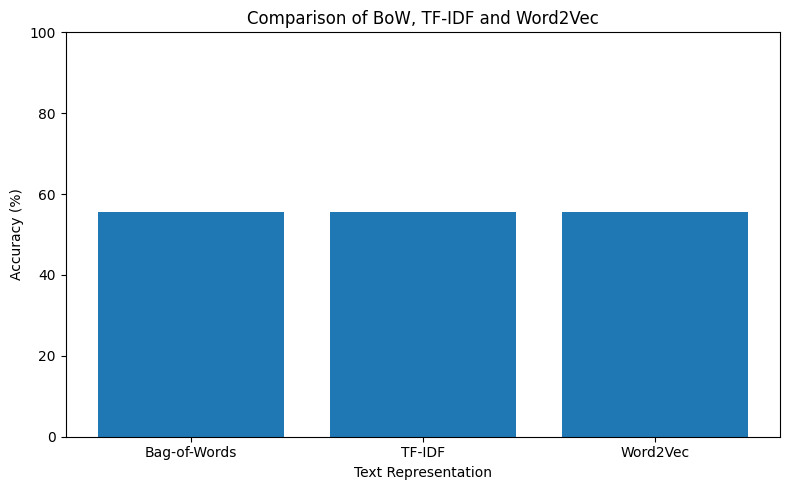

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Create comparison table
comparison = pd.DataFrame({
    "Representation": list(results.keys()),
    "Accuracy (%)": [
        round(value * 100, 2)
        for value in results.values()
    ]
})

print("FINAL PERFORMANCE COMPARISON")
print("--------------------------------")
print(comparison.to_string(index=False))

# Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Representation"],
    comparison["Accuracy (%)"]
)

plt.xlabel("Text Representation")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of BoW, TF-IDF and Word2Vec")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [33]:
print("OBSERVATION")
print("-----------------------------------")

print("1. Bag-of-Words represents text using word frequencies.")

print("2. TF-IDF assigns importance to words based on their "
      "frequency in documents.")

print("3. Word2Vec represents words as dense numerical vectors "
      "and captures contextual relationships.")

print("4. Cosine similarity is used to measure similarity "
      "between two documents.")

print("5. Logistic Regression is used for downstream text "
      "classification.")

print("\nFinal Accuracy Comparison:")
print(comparison.to_string(index=False))

print("\nNLP Lab Program Executed Successfully!")

OBSERVATION
-----------------------------------
1. Bag-of-Words represents text using word frequencies.
2. TF-IDF assigns importance to words based on their frequency in documents.
3. Word2Vec represents words as dense numerical vectors and captures contextual relationships.
4. Cosine similarity is used to measure similarity between two documents.
5. Logistic Regression is used for downstream text classification.

Final Accuracy Comparison:
Representation  Accuracy (%)
  Bag-of-Words         55.56
        TF-IDF         55.56
      Word2Vec         55.56

NLP Lab Program Executed Successfully!
